In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



In [4]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [5]:
df.columns = df.columns.str.strip().str.lower()
df = df.drop_duplicates()

X = df.drop(columns=["target"])
y = df["target"].astype(int)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget proportions:")
print(y.value_counts(normalize=True))

Dataset shape: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target proportions:
target
1    0.543046
0    0.456954
Name: proportion, dtype: float64


In [6]:
def train_and_evaluate(X_train, X_test, y_train, y_test):

    # Handle missing values
    imputer = SimpleImputer(strategy="median")

    X_train = pd.DataFrame(
        imputer.fit_transform(X_train),
        columns=X_train.columns,
        index=X_train.index
    )

    X_test = pd.DataFrame(
        imputer.transform(X_test),
        columns=X_test.columns,
        index=X_test.index
    )

    # Train model
    model = RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )

    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Calculate metrics
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

In [7]:
random_results = []

for seed in range(10):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=None
    )

    metrics = train_and_evaluate(
        X_train,
        X_test,
        y_train,
        y_test
    )

    random_results.append({
        "Split": seed + 1,
        "Random Seed": seed,
        "Train Positive Rate": y_train.mean(),
        "Test Positive Rate": y_test.mean(),
        **metrics
    })


random_df = pd.DataFrame(random_results)

print("Randomized Split Results")
display(random_df)

Randomized Split Results


,Split,Random Seed,Train Positive Rate,Test Positive Rate,Accuracy,Precision,Recall,F1 Score
0,1,0,0.531120,0.590164,0.819672,0.837838,0.861111,0.849315
1,2,1,0.535270,0.573770,0.786885,0.823529,0.800000,0.811594
2,3,2,0.556017,0.491803,0.786885,0.774194,0.800000,0.786885
3,4,3,0.551867,0.508197,0.836066,0.800000,0.903226,0.848485
4,5,4,0.543568,0.540984,0.754098,0.764706,0.787879,0.776119
5,6,5,0.526971,0.606557,0.721311,0.794118,0.729730,0.760563
6,7,6,0.564315,0.459016,0.803279,0.750000,0.857143,0.800000
7,8,7,0.547718,0.524590,0.852459,0.870968,0.843750,0.857143
8,9,8,0.543568,0.540984,0.786885,0.738095,0.939394,0.826667
9,10,9,0.522822,0.622951,0.803279,0.882353,0.789474,0.833333


In [8]:
stratified_results = []

for seed in range(10):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    metrics = train_and_evaluate(
        X_train,
        X_test,
        y_train,
        y_test
    )

    stratified_results.append({
        "Split": seed + 1,
        "Random Seed": seed,
        "Train Positive Rate": y_train.mean(),
        "Test Positive Rate": y_test.mean(),
        **metrics
    })


stratified_df = pd.DataFrame(stratified_results)

print("Stratified Split Results")
display(stratified_df)

Stratified Split Results


,Split,Random Seed,Train Positive Rate,Test Positive Rate,Accuracy,Precision,Recall,F1 Score
0,1,0,0.543568,0.540984,0.868852,0.878788,0.878788,0.878788
1,2,1,0.543568,0.540984,0.885246,0.933333,0.848485,0.888889
2,3,2,0.543568,0.540984,0.868852,0.878788,0.878788,0.878788
3,4,3,0.543568,0.540984,0.754098,0.736842,0.848485,0.788732
4,5,4,0.543568,0.540984,0.934426,0.914286,0.969697,0.941176
5,6,5,0.543568,0.540984,0.819672,0.823529,0.848485,0.835821
6,7,6,0.543568,0.540984,0.770492,0.806452,0.757576,0.781250
7,8,7,0.543568,0.540984,0.786885,0.794118,0.818182,0.805970
8,9,8,0.543568,0.540984,0.770492,0.827586,0.727273,0.774194
9,10,9,0.543568,0.540984,0.754098,0.750000,0.818182,0.782609


In [9]:
metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

stability_results = []

for method, results in [
    ("Randomized", random_df),
    ("Stratified", stratified_df)
]:

    for metric in metrics_columns:

        stability_results.append({
            "Split Method": method,
            "Metric": metric,
            "Mean": results[metric].mean(),
            "Standard Deviation": results[metric].std(),
            "Minimum": results[metric].min(),
            "Maximum": results[metric].max()
        })


stability_df = pd.DataFrame(stability_results)

display(stability_df)

,Split Method,Metric,Mean,Standard Deviation,Minimum,Maximum
0,Randomized,Accuracy,0.795082,0.038056,0.721311,0.852459
1,Randomized,Precision,0.803580,0.049390,0.738095,0.882353
2,Randomized,Recall,0.831171,0.061896,0.729730,0.939394
3,Randomized,F1 Score,0.815011,0.033415,0.760563,0.857143
4,Stratified,Accuracy,0.821311,0.063937,0.754098,0.934426
5,Stratified,Precision,0.834372,0.066097,0.736842,0.933333
6,Stratified,Recall,0.839394,0.067079,0.727273,0.969697
7,Stratified,F1 Score,0.835622,0.058046,0.774194,0.941176


In [10]:
training_sizes = [0.60, 0.70, 0.80, 0.90]

size_results = []

for train_size in training_sizes:

    test_size = 1 - train_size

    for seed in range(5):

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            train_size=train_size,
            random_state=seed,
            stratify=y
        )

        metrics = train_and_evaluate(
            X_train,
            X_test,
            y_train,
            y_test
        )

        size_results.append({
            "Training Size": train_size,
            "Testing Size": test_size,
            "Random Seed": seed,
            **metrics
        })


size_df = pd.DataFrame(size_results)

display(size_df)

,Training Size,Testing Size,Random Seed,Accuracy,Precision,Recall,F1 Score
0,0.6,0.4,0,0.867769,0.857143,0.909091,0.882353
1,0.6,0.4,1,0.842975,0.821918,0.909091,0.863309
2,0.6,0.4,2,0.834711,0.828571,0.878788,0.852941
3,0.6,0.4,3,0.801653,0.808824,0.833333,0.820896
4,0.6,0.4,4,0.851240,0.824324,0.924242,0.871429
5,0.7,0.3,0,0.868132,0.849057,0.918367,0.882353
6,0.7,0.3,1,0.835165,0.814815,0.897959,0.854369
7,0.7,0.3,2,0.846154,0.872340,0.836735,0.854167
8,0.7,0.3,3,0.824176,0.811321,0.877551,0.843137
9,0.7,0.3,4,0.857143,0.821429,0.938776,0.876190


In [11]:
size_summary = size_df.groupby(
    "Training Size"
)[metrics_columns].agg(["mean", "std"])

print("Performance Across Different Training Sizes")
display(size_summary)

Performance Across Different Training Sizes


Accuracy           Precision              Recall            \
                   mean       std      mean       std      mean       std   
Training Size                                                               
0.6            0.839669  0.024516  0.828156  0.017803  0.890909  0.036174   
0.7            0.846154  0.017375  0.833792  0.026158  0.893878  0.039256   
0.8            0.862295  0.066186  0.868407  0.077209  0.884848  0.049793   
0.9            0.870968  0.064516  0.892895  0.103185  0.882353  0.058824   

               F1 Score            
                   mean       std  
Training Size                      
0.6            0.858186  0.023472  
0.7            0.862043  0.016515  
0.8            0.875275  0.054869  
0.9            0.883921  0.054562

In [15]:
# Fixed stratified test split
X_train_full, X_test_fixed, y_train_full, y_test_fixed = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create training data for different distributions
def create_distribution(
    X_train,
    y_train,
    class_0_fraction,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    class_0_indices = np.where(
        y_train.values == 0
    )[0]

    class_1_indices = np.where(
        y_train.values == 1
    )[0]

    total = len(y_train)

    desired_0 = int(total * class_0_fraction)
    desired_1 = total - desired_0

    if desired_0 > len(class_0_indices):
        raise ValueError("Not enough class 0 samples.")

    if desired_1 > len(class_1_indices):
        raise ValueError("Not enough class 1 samples.")

    selected_0 = rng.choice(
        class_0_indices,
        size=desired_0,
        replace=False
    )

    selected_1 = rng.choice(
        class_1_indices,
        size=desired_1,
        replace=False
    )

    selected_indices = np.concatenate([
        selected_0,
        selected_1
    ])

    rng.shuffle(selected_indices)

    return (
        X_train.iloc[selected_indices],
        y_train.iloc[selected_indices]
    )

In [23]:

import numpy as np
import pandas as pd

distribution_settings = {
    "Original Distribution": 1 - y_train_full.mean(),
    "Class 0: 70%": 0.70,
    "Class 0: 60%": 0.60,
    "Balanced": 0.50,
    "Class 0: 40%": 0.40
}

distribution_results = []

for distribution_name, class_0_fraction in distribution_settings.items():

    class_0_indices = np.where(
        y_train_full.values == 0
    )[0]

    class_1_indices = np.where(
        y_train_full.values == 1
    )[0]

    total_samples = len(y_train_full)

    desired_0 = int(round(total_samples * class_0_fraction))
    desired_1 = total_samples - desired_0

    selected_0 = np.random.default_rng(42).choice(
        class_0_indices,
        size=desired_0,
        replace=desired_0 > len(class_0_indices)
    )

    selected_1 = np.random.default_rng(43).choice(
        class_1_indices,
        size=desired_1,
        replace=desired_1 > len(class_1_indices)
    )

    selected_indices = np.concatenate([
        selected_0,
        selected_1
    ])

    np.random.default_rng(44).shuffle(selected_indices)

    X_changed = X_train_full.iloc[selected_indices].copy()
    y_changed = y_train_full.iloc[selected_indices].copy()

    metrics = train_and_evaluate(
        X_changed,
        X_test_fixed,
        y_changed,
        y_test_fixed
    )

    distribution_results.append({
        "Distribution": distribution_name,
        "Actual Class 0 Rate": (y_changed == 0).mean(),
        "Actual Class 1 Rate": (y_changed == 1).mean(),
        "Training Samples": len(y_changed),
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1 Score": metrics["F1 Score"]
    })


distribution_df = pd.DataFrame(distribution_results)

print("MODEL PERFORMANCE UNDER DIFFERENT DATA DISTRIBUTIONS")

display(distribution_df)

MODEL PERFORMANCE UNDER DIFFERENT DATA DISTRIBUTIONS


,Distribution,Actual Class 0 Rate,Actual Class 1 Rate,Training Samples,Accuracy,Precision,Recall,F1 Score
0,Original Distribution,0.456432,0.543568,241,0.754098,0.764706,0.787879,0.776119
1,Class 0: 70%,0.701245,0.298755,241,0.754098,0.846154,0.666667,0.745763
2,Class 0: 60%,0.601660,0.398340,241,0.754098,0.781250,0.757576,0.769231
3,Balanced,0.497925,0.502075,241,0.754098,0.764706,0.787879,0.776119
4,Class 0: 40%,0.398340,0.601660,241,0.770492,0.787879,0.787879,0.787879


In [25]:


repeated_distribution_results = []

for distribution_name, class_0_fraction in distribution_settings.items():

    for seed in range(5):

        rng = np.random.default_rng(seed)

        class_0_indices = np.where(
            y_train_full.values == 0
        )[0]

        class_1_indices = np.where(
            y_train_full.values == 1
        )[0]

        total_samples = len(y_train_full)

        desired_0 = int(round(total_samples * class_0_fraction))
        desired_1 = total_samples - desired_0

        selected_0 = rng.choice(
            class_0_indices,
            size=desired_0,
            replace=desired_0 > len(class_0_indices)
        )

        selected_1 = rng.choice(
            class_1_indices,
            size=desired_1,
            replace=desired_1 > len(class_1_indices)
        )

        selected_indices = np.concatenate([
            selected_0,
            selected_1
        ])

        rng.shuffle(selected_indices)

        X_changed = X_train_full.iloc[selected_indices].copy()
        y_changed = y_train_full.iloc[selected_indices].copy()

        metrics = train_and_evaluate(
            X_changed,
            X_test_fixed,
            y_changed,
            y_test_fixed
        )

        repeated_distribution_results.append({
            "Distribution": distribution_name,
            "Random Seed": seed,
            "Class 0 Rate": (y_changed == 0).mean(),
            "Class 1 Rate": (y_changed == 1).mean(),
            **metrics
        })

repeated_distribution_df = pd.DataFrame(
    repeated_distribution_results
)

display(repeated_distribution_df)

,Distribution,Random Seed,Class 0 Rate,Class 1 Rate,Accuracy,Precision,Recall,F1 Score
0,Original Distribution,0,0.456432,0.543568,0.770492,0.806452,0.757576,0.781250
1,Original Distribution,1,0.456432,0.543568,0.786885,0.812500,0.787879,0.800000
2,Original Distribution,2,0.456432,0.543568,0.786885,0.812500,0.787879,0.800000
3,Original Distribution,3,0.456432,0.543568,0.786885,0.812500,0.787879,0.800000
4,Original Distribution,4,0.456432,0.543568,0.770492,0.787879,0.787879,0.787879
5,Class 0: 70%,0,0.701245,0.298755,0.786885,0.916667,0.666667,0.771930
6,Class 0: 70%,1,0.701245,0.298755,0.754098,0.821429,0.696970,0.754098
7,Class 0: 70%,2,0.701245,0.298755,0.737705,0.793103,0.696970,0.741935
8,Class 0: 70%,3,0.701245,0.298755,0.688525,0.791667,0.575758,0.666667
9,Class 0: 70%,4,0.701245,0.298755,0.786885,0.884615,0.696970,0.779661


In [26]:

metrics_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

distribution_stability = repeated_distribution_df.groupby(
    "Distribution"
)[metrics_columns].agg(["mean", "std", "min", "max"])

print("DISTRIBUTION STABILITY SUMMARY")

display(distribution_stability)

DISTRIBUTION STABILITY SUMMARY


Accuracy                               Precision  \
                           mean       std       min       max      mean   
Distribution                                                              
Balanced               0.813115  0.021994  0.786885  0.836066  0.806984   
Class 0: 40%           0.770492  0.020078  0.754098  0.803279  0.803956   
Class 0: 60%           0.780328  0.021994  0.754098  0.803279  0.806608   
Class 0: 70%           0.750820  0.040819  0.688525  0.786885  0.841496   
Original Distribution  0.780328  0.008979  0.770492  0.786885  0.806366   

                                                       Recall            \
                            std       min       max      mean       std   
Distribution                                                              
Balanced               0.021694  0.777778  0.828571  0.860606  0.016598   
Class 0: 40%           0.026763  0.764706  0.827586  0.763636  0.049793   
Class 0: 60%           0.019162  0.787879  0.838710  0.781818  0.044947   
Class 0: 70%           0.056430  0.791667  0.916667  0.666667  0.052486   
Original Distribution  0.010661  0.787879  0.812500  0.781818  0.013552   

                                           F1 Score                      \
                            min       max      mean       std       min   
Distribution                                                              
Balanced               0.848485  0.878788  0.832907  0.018927  0.811594   
Class 0: 40%           0.696970  0.818182  0.782094  0.023546  0.754098   
Class 0: 60%           0.727273  0.848485  0.793413  0.024712  0.761905   
Class 0: 70%           0.575758  0.696970  0.742858  0.045089  0.666667   
Original Distribution  0.757576  0.787879  0.793826  0.008773  0.781250   

                                 
                            max  
Distribution                     
Balanced               0.852941  
Class 0: 40%           0.818182  
Class 0: 60%           0.823529  
Class 0: 70%           0.779661  
Original Distribution  0.800000

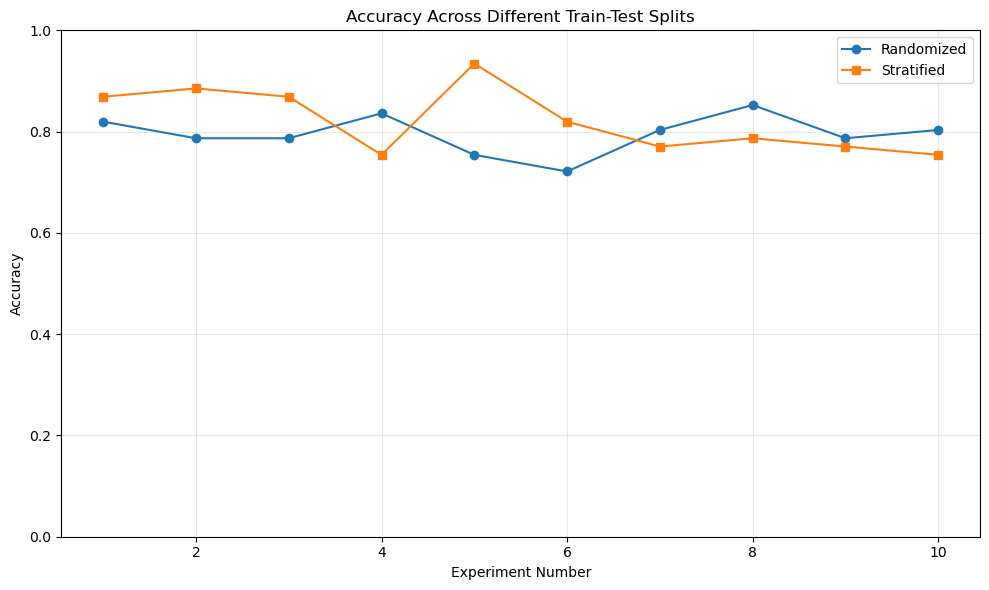

In [27]:


plt.figure(figsize=(10, 6))

plt.plot(
    random_df["Split"],
    random_df["Accuracy"],
    marker="o",
    label="Randomized"
)

plt.plot(
    stratified_df["Split"],
    stratified_df["Accuracy"],
    marker="s",
    label="Stratified"
)

plt.title("Accuracy Across Different Train-Test Splits")
plt.xlabel("Experiment Number")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

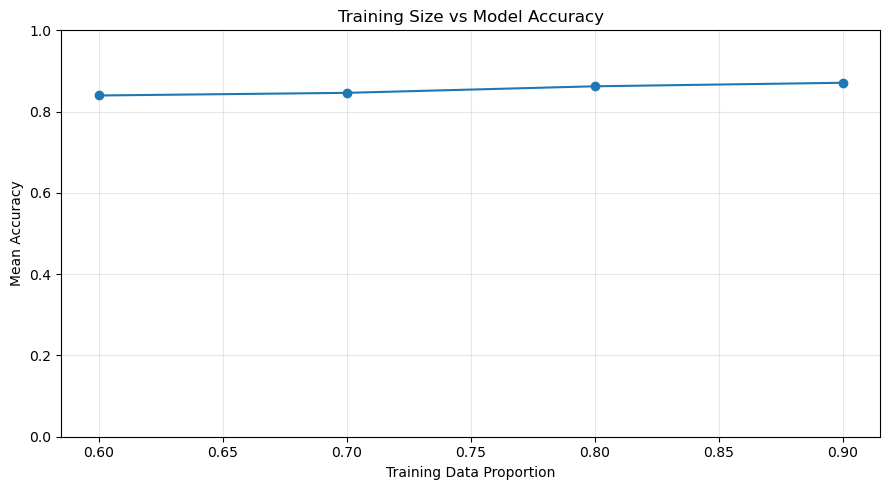

In [28]:


size_accuracy = size_df.groupby(
    "Training Size"
)["Accuracy"].mean()

plt.figure(figsize=(9, 5))

plt.plot(
    size_accuracy.index,
    size_accuracy.values,
    marker="o"
)

plt.title("Training Size vs Model Accuracy")
plt.xlabel("Training Data Proportion")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

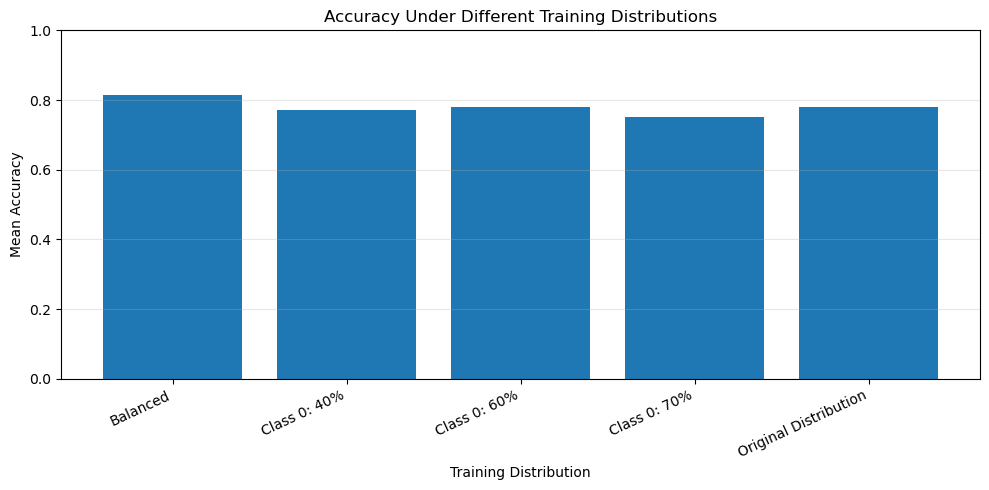

In [29]:


distribution_summary = repeated_distribution_df.groupby(
    "Distribution"
)[metrics_columns].mean()

plt.figure(figsize=(10, 5))

plt.bar(
    distribution_summary.index,
    distribution_summary["Accuracy"]
)

plt.title("Accuracy Under Different Training Distributions")
plt.xlabel("Training Distribution")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:


accuracy_std_random = random_df["Accuracy"].std()
accuracy_std_stratified = stratified_df["Accuracy"].std()

print("Randomized Accuracy Standard Deviation:",
      round(accuracy_std_random, 4))

print("Stratified Accuracy Standard Deviation:",
      round(accuracy_std_stratified, 4))

print("\nStability Result:")

if accuracy_std_stratified < accuracy_std_random:
    print("Stratified splitting was more stable in these experiments.")

elif accuracy_std_stratified > accuracy_std_random:
    print("Randomized splitting was more stable in these experiments.")

else:
    print("Both splitting methods had equal variation.")

print("\nLower standard deviation indicates greater stability.")

Randomized Accuracy Standard Deviation: 0.0381
Stratified Accuracy Standard Deviation: 0.0639

Stability Result:
Randomized splitting was more stable in these experiments.

Lower standard deviation indicates greater stability.


In [31]:


random_df.to_csv("randomized_split_results.csv", index=False)

stratified_df.to_csv("stratified_split_results.csv", index=False)

stability_df.to_csv("split_stability_summary.csv", index=False)

size_df.to_csv("training_size_results.csv", index=False)

distribution_df.to_csv("distribution_shift_results.csv", index=False)

repeated_distribution_df.to_csv(
    "repeated_distribution_results.csv",
    index=False
)

distribution_stability.to_csv(
    "distribution_stability_summary.csv"
)

print("All experiment results exported successfully.")

All experiment results exported successfully.


In [32]:

report = []

report.append("# Model Stability and Distribution Analysis\n")

report.append("## Objective\n")
report.append(
    "The experiment evaluates model performance across randomized "
    "and stratified train-test splits, different training sizes, "
    "and different class distributions.\n"
)

report.append("\n## Randomized Split Results\n")
report.append(random_df.to_string(index=False))

report.append("\n## Stratified Split Results\n")
report.append(stratified_df.to_string(index=False))

report.append("\n## Stability Summary\n")
report.append(stability_df.to_string(index=False))

report.append("\n## Training Size Results\n")
report.append(size_df.to_string(index=False))

report.append("\n## Distribution Results\n")
report.append(distribution_df.to_string(index=False))

report.append("\n## Repeated Distribution Stability\n")
report.append(distribution_stability.to_string())

report.append("\n## Conclusion\n")
report.append(
    "The experiments show how changes in training sample selection, "
    "class distribution and training size affect predictive performance. "
    "Mean scores represent average performance, while standard deviations "
    "measure variation across repeated experiments. Sampling with "
    "replacement may introduce duplicate observations, so the results "
    "should be interpreted as a controlled class-balancing experiment "
    "rather than a simulation of every real-world distribution shift.\n"
)

with open(
    "model_stability_analysis_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report))

print("Final model stability report generated successfully.")

Final model stability report generated successfully.
